# Module 6 — Part A: Three portfolios, backtested

**The brief (verbatim):**
> **Module 6 — Portfolio Optimization**
> Dataset: nova_market_data.csv (same dataset as Module 5)
> One must transform ML predictions into an actual portfolio. Compare strategies- Equal-weight portfolio, Traditional Markowitz portfolio, ML-predicted-return portfolio. Perform backtesting to demonstrate performance and generate performance metrics.

**Where this sits:** Module 5 forecast each stock's next-month return (ridge regression, decision M5-15) → **Part A: turn forecasts into portfolio weights, replay every month with trading costs, compare** → Part B: VaR and stress tests → Module 9 ("Equity investments").

**The strategies** (all reset at each month-end, decision M6-01):
- **Equal weight:** 1 ÷ 15 = 6.67% in each stock. Uses no forecast.
- **Markowitz (past returns):** the weights with the most return per unit of risk (maximum Sharpe), using each stock's average return and co-movement over the past year (decision M6-02).
- **ML (ridge forecasts):** the same optimiser, with ridge's forecast of next month's return in place of the past average (decision M6-08). Same risk estimate, so any difference comes from the forecasts.
- **Top 5 (Module 5):** the 5 highest ridge forecasts, 20% each. Shown for comparison.

**Terms (details in `docs/documentation.md` section 9):**
- **Weight:** the share of the money in a stock; weights add up to 100%.
- **Backtest:** replay a strategy month by month on past data, using only what was known at each date, as if really trading.
- **Test (out-of-sample) months:** the 43 months 31 Jan 2023 – 31 Aug 2026; each was decided using only earlier data (decision M6-09).
- **CAGR:** steady yearly growth rate. **Volatility:** how much returns swing a year. **Sharpe:** return above a safe bond (6.8% a year) per unit of swing; higher is better, above 1 good.
- **Maximum drawdown:** worst fall from a high. **Turnover:** share of the portfolio traded per rebalance (buys + sells).
- **p:** the chance luck alone gives a gap this big; line 0.05 ÷ 3 = 0.017 (0.05 = the usual 1-in-20 chance of being fooled; ÷ 3 comparisons).

| Step | What it does |
| --- | --- |
| 0 | Setup and the agreed settings |
| 1 | The data: daily returns, rebalance dates, ridge forecasts |
| 2 | Turning forecasts into weights: the optimiser |
| 3 | The backtest: daily values, monthly resets, trading costs |
| 4 | Results: every measure, and the luck test |
| 5 | Growth, falls and weights over time (charts) |
| 6 | Checks: other trading costs, and a 0% risk-free rate |
| 7 | What it means in ₹ |
| 8 | What the results say |
| 9 | Save the outputs |

**Decisions used** (in `docs/decisions.md`): M6-01 monthly · M6-02 maximum Sharpe · M6-03 1-year window, 261-day year · M6-04 cost 0.15% · M6-05 risk-free 6.8% · M6-08 ML portfolio · M6-09 test period · M6-10 measures and luck test.

## 0. Setup and the agreed settings
Works locally and in Google Colab. Takes under a minute (43 months × 3 optimisations, plus the cost checks).

| Setting | Value | Why (decision) |
| --- | --- | --- |
| Days in a year | 261 | This data has every weekday and no holidays; 252 is the US convention (M6-03) |
| Risk estimate | Past 261 trading days, Ledoit–Wolf shrinkage | One year; shrinkage steadies noisy co-movement estimates (M6-03) |
| Largest weight | 25% per stock, no short selling | Stops the optimiser putting everything in one stock (M6-02) |
| Trading cost | 0.15% of every ₹ bought or sold; checks 0%, 0.10%, 0.30% | Indian STT 0.1% each way + stamp duty + charges + institutional brokerage and price impact (M6-04) |
| Risk-free rate | 6.8% a year, fixed; check 0% | The `Interest_Rate` column is random; 6.8% ≈ Indian Treasury bills (M6-05) |

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # stops a harmless Windows warning
# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_06_portfolio_optimization"
M5_DIR = PROJECT_ROOT / "module_05_equity_markets"
OUT_DIR = MODULE_DIR / "outputs" / "partA"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
sys.path.insert(0, str(M5_DIR / "helpers"))           # Module 5's data helper: same data, same dates
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize
from sklearn.covariance import LedoitWolf

from m05_data import load_market, month_end_dates
from m06_metrics import (TRADING_DAYS, RISK_FREE_ANNUAL, performance_table, cagr, sharpe, max_drawdown,
                         annual_volatility, daily_rate)
from m06_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

WINDOW = TRADING_DAYS              # 261 trading days = 1 year of history for the risk estimate (M6-03)
CAP = 0.25                         # largest weight in one stock (M6-02)
COST = 0.0015                      # 0.15% of every ₹ bought or sold (M6-04)
COST_CHECKS = [0.0, 0.0010, 0.0015, 0.0030]
DAYS_A_MONTH = TRADING_DAYS / 12   # 21.75 trading days in an average month
RF_MONTH = (1 + RISK_FREE_ANNUAL) ** (1 / 12) - 1
START_CRORE = 100                  # illustrative ₹100 crore
EW, MK, ML, T5 = "Equal weight", "Markowitz (past returns)", "ML (ridge forecasts)", "Top 5 (Module 5)"
STRATEGIES = [EW, MK, ML, T5]
COMPARED = [MK, ML, T5]            # each compared with equal weight
LINE = 0.05 / len(COMPARED)        # 0.05 ÷ 3 ≈ 0.017 (M6-10)
COLOURS = {EW: INK, MK: BLUE, ML: ORANGE, T5: AQUA}
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(f"Year = {TRADING_DAYS} trading days; risk-free {RISK_FREE_ANNUAL:.1%} a year = {RF_MONTH:.3%} a month; "
      f"cost {COST:.2%} per ₹ traded; luck line 0.05 ÷ {len(COMPARED)} = {LINE:.3f}")

Outputs go to: module_06_portfolio_optimization/outputs/partA
Year = 261 trading days; risk-free 6.8% a year = 0.550% a month; cost 0.15% per ₹ traded; luck line 0.05 ÷ 3 = 0.017


## 1. The data: daily returns, rebalance dates, ridge forecasts

- **Daily returns:** each stock's `Return` column (today's close ÷ yesterday's close − 1; checked in Module 5).
- **Rebalance dates:** the 43 test month-ends from Module 5 (31 Jan 2023 – 31 Jul 2026); each portfolio is held to the next month-end, the last to 31 Aug 2026 (decision M6-09).
- **ML forecasts:** ridge regression's walk-forward forecast of each stock's next-month return, from `module_05_equity_markets/outputs/task1/FINAL_M5_T1_return_predictions.csv` (decision M5-15). Each was made using only earlier months.
- **Check: a year in this data** = 261 rows (every weekday, no holidays).

In [2]:
mkt = load_market()
R = mkt.pivot(index="Date", columns="Ticker", values="Return").sort_index()     # days × 15 stocks
TICKERS = list(R.columns)
pred = pd.read_csv(M5_DIR / "outputs" / "task1" / "FINAL_M5_T1_return_predictions.csv", parse_dates=["Date"])
ML_FORECAST = pred.pivot(index="Date", columns="Ticker", values="Pred: Ridge regression")[TICKERS]
DATES = list(ML_FORECAST.index)                                 # 43 rebalance dates
LAST = month_end_dates(mkt)[-1]                                 # 31 Aug 2026
HELD_UNTIL = dict(zip(DATES, DATES[1:] + [LAST]))

rows_a_year = R.index.year.value_counts().sort_index()
print(f"{len(R):,} trading days × {len(TICKERS)} stocks; rows per full year: "
      + ", ".join(f"{y}: {n}" for y, n in rows_a_year.items() if 2022 <= y <= 2025))
print(f"Rebalance dates: {len(DATES)} ({DATES[0]:%d %b %Y} – {DATES[-1]:%d %b %Y}), last held to {LAST:%d %b %Y}")
test_days = R.loc[(R.index > DATES[0]) & (R.index <= LAST)]
print(f"Test days: {len(test_days)} = {len(test_days) / TRADING_DAYS:.2f} years of {TRADING_DAYS} days "
      f"(with 252 it would wrongly be {len(test_days) / 252:.2f} years)")
print(f"Ridge forecasts: {ML_FORECAST.stack().min():+.1%} to {ML_FORECAST.stack().max():+.1%} a month; "
      f"months where no stock beats the risk-free {RF_MONTH:.2%}: {(ML_FORECAST.max(axis=1) <= RF_MONTH).sum()}")

1,457 trading days × 15 stocks; rows per full year: 2022: 260, 2023: 260, 2024: 262, 2025: 261
Rebalance dates: 43 (31 Jan 2023 – 31 Jul 2026), last held to 31 Aug 2026
Test days: 934 = 3.58 years of 261 days (with 252 it would wrongly be 3.71 years)
Ridge forecasts: -4.7% to +6.0% a month; months where no stock beats the risk-free 0.55%: 0


## 2. Turning forecasts into weights: the optimiser

**Markowitz maximum Sharpe** (decision M6-02), at each month-end, using only data up to that day:

```text
Expected monthly return of each stock, μ:
    Markowitz (past returns): average daily return over the past 261 days × 21.75 (days in a month)
    ML (ridge forecasts):     ridge's forecast of next month's return
How stocks move together, Σ: covariance of the past 261 days' daily returns (Ledoit–Wolf), × 21.75
Choose weights w to maximise   Sharpe = (w·μ − risk-free) ÷ √(w·Σ·w)
    subject to: weights add up to 1; each weight between 0 and 25%
```

- **w·μ** = the portfolio's expected return (each weight × its stock's expected return, added up). **√(w·Σ·w)** = the portfolio's expected swing; it is lower when stocks don't move together (diversification).
- **Ledoit–Wolf shrinkage:** the raw covariance from one year of data is noisy; shrinkage pulls it part-way toward a simple average structure, which steadies the weights.
- **Minimum-risk check:** the other common Markowitz version ignores μ and minimises √(w·Σ·w). It is computed below to show how close it is to equal weight.

In [3]:
def risk_estimate(day) -> np.ndarray:
    """Monthly covariance of the 15 stocks from the past WINDOW trading days up to `day` (Ledoit–Wolf)."""
    history = R.loc[:day].iloc[-WINDOW:]
    return LedoitWolf().fit(history.values).covariance_ * DAYS_A_MONTH


def max_sharpe(mu: np.ndarray, cov: np.ndarray) -> np.ndarray:
    """Long-only weights (each 0–CAP, adding to 1) with the highest (w·μ − risk-free) ÷ √(w·Σ·w).
    SLSQP = a standard optimiser for smooth objectives with limits; starts from equal weight."""
    n = len(mu)
    objective = lambda w: -(w @ mu - RF_MONTH) / np.sqrt(w @ cov @ w)       # minus, because the optimiser minimises
    result = minimize(objective, np.full(n, 1 / n), method="SLSQP", bounds=[(0, CAP)] * n,
                      constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}], options={"maxiter": 500})
    w = np.clip(result.x, 0, None)
    return w / w.sum()


def min_risk(cov: np.ndarray) -> np.ndarray:
    """Long-only weights (0–CAP, adding to 1) with the lowest expected swing √(w·Σ·w)."""
    n = cov.shape[0]
    result = minimize(lambda w: w @ cov @ w, np.full(n, 1 / n), method="SLSQP", bounds=[(0, CAP)] * n,
                      constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    return result.x


def target_weights(strategy: str, day) -> tuple[np.ndarray, np.ndarray | None]:
    """Weights for `strategy` on rebalance date `day`, and the expected returns it used (None if none)."""
    if strategy == EW:
        return np.full(15, 1 / 15), None
    if strategy == T5:
        w = np.zeros(15)
        w[np.argsort(-ML_FORECAST.loc[day].values, kind="stable")[:5]] = 0.2
        return w, ML_FORECAST.loc[day].values
    cov = risk_estimate(day)
    if strategy == MK:
        mu = R.loc[:day].iloc[-WINDOW:].mean().values * DAYS_A_MONTH
    else:
        mu = ML_FORECAST.loc[day].values
    return max_sharpe(mu, cov), mu


# Example: the first rebalance date
example = pd.DataFrame({"Ticker": TICKERS})
for s in STRATEGIES:
    example[s] = target_weights(s, DATES[0])[0]
example["Past-year average (a month)"] = R.loc[:DATES[0]].iloc[-WINDOW:].mean().values * DAYS_A_MONTH
example["Ridge forecast"] = ML_FORECAST.loc[DATES[0]].values
print(f"Weights on {DATES[0]:%d %b %Y}:")
display(example.style.format({**{s: "{:.1%}" for s in STRATEGIES}, "Past-year average (a month)": "{:+.2%}",
                              "Ridge forecast": "{:+.2%}"}).hide(axis="index"))

gap = [np.abs(min_risk(risk_estimate(d)) - 1 / 15).max() for d in DATES]
print(f"Minimum-risk Markowitz vs equal weight: largest difference in any stock's weight over 43 months = {max(gap):.2%} "
      f"(stocks alike and independent → spreading evenly is the lowest-risk mix)")

Weights on 31 Jan 2023:


Ticker,Equal weight,Markowitz (past returns),ML (ridge forecasts),Top 5 (Module 5),Past-year average (a month),Ridge forecast
AXISBANK,6.7%,17.3%,0.0%,0.0%,+3.19%,-3.38%
BHARTIARTL,6.7%,16.2%,0.0%,0.0%,+3.02%,-2.42%
HDFCBANK,6.7%,14.9%,0.0%,0.0%,+2.82%,+0.18%
HINDUNILVR,6.7%,0.0%,25.0%,20.0%,-1.71%,+5.96%
ICICIBANK,6.7%,8.0%,0.0%,0.0%,+1.77%,-3.17%
INFY,6.7%,3.2%,0.0%,0.0%,+1.04%,-0.34%
ITC,6.7%,0.0%,17.9%,20.0%,-0.14%,+3.36%
KOTAKBANK,6.7%,0.0%,11.7%,20.0%,-1.17%,+2.25%
LT,6.7%,0.0%,3.1%,0.0%,+0.25%,+0.73%
MARUTI,6.7%,11.4%,0.0%,0.0%,+2.29%,-2.14%


Minimum-risk Markowitz vs equal weight: largest difference in any stock's weight over 43 months = 0.00% (stocks alike and independent → spreading evenly is the lowest-risk mix)


## 3. The backtest: daily values, monthly resets, trading costs

For each strategy and each month:
1. On the rebalance date, compute the target weights (step 2) using data up to that day only.
2. **Trade** from the weights held (which drifted during the month as prices moved) to the targets. **Turnover** = sum of |target − held| across the 15 stocks; it counts both buys and sells. **Cost** = 0.15% × turnover, taken from the first day's return.
3. **Hold** to the next month-end without trading; each day's portfolio return = the value-weighted average of the 15 stocks' returns, so weights drift with prices.

```text
Example: held 6.0% in a stock that rose, target 6.67% → buy 0.67%; another fell from 7.5% to 6.67% → sell 0.83%
Turnover = 0.67% + 0.83% + … ; cost = 0.15% × turnover
```

The first month buys from cash (turnover 100% for every strategy); average turnover is reported over the 42 later months.

In [4]:
def backtest(strategy: str, cost: float = COST) -> dict:
    """Replay `strategy` over the 43 test months. Returns daily returns (after costs), turnover per month,
    and the target weights on each rebalance date."""
    daily, turnovers, weights, expected, held_before = [], [], [], [], []
    held = np.zeros(15)                                         # start in cash
    for day in DATES:
        target, mu = target_weights(strategy, day)
        turn = np.abs(target - held).sum()
        held_before.append(held.copy())                          # weights just before the trade (drifted)
        turnovers.append(turn)
        weights.append(target)
        expected.append(mu)
        days = R.loc[(R.index > day) & (R.index <= HELD_UNTIL[day])]
        growth = (1 + days).cumprod().values                    # each stock's value path (start = 1)
        value = growth @ target                                 # portfolio value path, weights drifting
        r = np.diff(np.concatenate([[1.0], value])) / np.concatenate([[1.0], value[:-1]])
        r[0] -= cost * turn                                     # trading cost on the rebalance
        daily.append(pd.Series(r, index=days.index))
        held = growth[-1] * target / value[-1]                  # drifted weights at the next month-end
    return {"daily": pd.concat(daily), "turnover": np.array(turnovers), "weights": np.array(weights),
            "expected": expected, "held_before": np.array(held_before)}


runs = {s: backtest(s) for s in STRATEGIES}
daily = pd.DataFrame({s: runs[s]["daily"] for s in STRATEGIES})
print(f"Daily returns: {daily.shape[0]} days × {daily.shape[1]} strategies ({daily.index[0]:%d %b %Y} – {daily.index[-1]:%d %b %Y})")
print("Average turnover a month (after the first):", ", ".join(f"{s} {runs[s]['turnover'][1:].mean():.0%}" for s in STRATEGIES))

Daily returns: 934 days × 4 strategies (01 Feb 2023 – 31 Aug 2026)
Average turnover a month (after the first): Equal weight 7%, Markowitz (past returns) 33%, ML (ridge forecasts) 90%, Top 5 (Module 5) 99%


## 4. Results: every measure, and the luck test

**The measures, in plain words** (good is in brackets):
- **CAGR** (higher): steady yearly growth. **Volatility** (lower): yearly swing.
- **Sharpe** (higher; above 1 good): (return − 6.8% safe rate) ÷ volatility. **Sortino** (higher): the same, counting only downside swings.
- **Maximum drawdown** (closer to 0): worst fall from a high. **Calmar** (higher): CAGR ÷ |worst fall|.
- **Tracking error:** how far a strategy wanders from equal weight a year (the size of the bet). **Information ratio** (higher; 0.5 good): extra yearly return over equal weight ÷ tracking error.
- **VaR 95%, 1 day** (smaller): the loss not exceeded on 95% of days. **CVaR 95%** (smaller): the average loss on the worst 5% of days. (Part B goes further.)
- **Turnover** (lower): share of the portfolio traded each month.
- **p (vs equal weight):** t-test on the 43 monthly differences from equal weight; real if below 0.05 ÷ 3 = 0.017.

**Not used:** alpha and beta need a real market index, which this data lacks (`Market_Return` is random); the information ratio plays alpha's role here (`docs/documentation.md` 9.2).

In [5]:
def monthly(r: pd.Series) -> pd.Series:
    """Compound daily returns into each holding month (keyed by the rebalance date)."""
    key = pd.Series(np.searchsorted(np.array(DATES, dtype="datetime64[ns]"), r.index.values, side="left") - 1, index=r.index)
    return (1 + r).groupby(key.values).prod() - 1


rows = []
for s in STRATEGIES:
    row = {"Strategy": s, **performance_table(daily[s], benchmark=None if s == EW else daily[EW]),
           "Turnover a month": runs[s]["turnover"][1:].mean(),
           "Largest weight (average)": runs[s]["weights"].max(axis=1).mean(),
           "Stocks held above 1% (average)": (runs[s]["weights"] > 0.01).sum(axis=1).mean()}
    if s != EW:
        diff = monthly(daily[s]) - monthly(daily[EW])
        row["p (vs equal weight)"] = float(stats.ttest_1samp(diff, 0).pvalue)
        row["Months beating equal weight"] = int((diff > 0).sum())
        row["Beats equal weight?"] = "Yes" if row["p (vs equal weight)"] < LINE and diff.mean() > 0 else "No"
    rows.append(row)
results = pd.DataFrame(rows)
FMT = {"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Sharpe": "{:.2f}", "Sortino": "{:.2f}", "Maximum drawdown": "{:.1%}",
       "Calmar": "{:.2f}", "VaR 95% (1 day, historical)": "{:.2%}", "VaR 95% (1 day, parametric)": "{:.2%}",
       "CVaR 95% (1 day)": "{:.2%}", "Tracking error": "{:.1%}", "Information ratio": "{:+.2f}", "Turnover a month": "{:.0%}",
       "Largest weight (average)": "{:.0%}", "Stocks held above 1% (average)": "{:.1f}", "p (vs equal weight)": "{:.2f}",
       "Months beating equal weight": "{:.0f}"}
print(f"43 test months, cost {COST:.2%} per ₹ traded, risk-free {RISK_FREE_ANNUAL:.1%}; line for 'beats equal weight' {LINE:.3f}")
display(results.style.format(FMT, na_rep="—").hide(axis="index"))

43 test months, cost 0.15% per ₹ traded, risk-free 6.8%; line for 'beats equal weight' 0.017


Strategy,CAGR,Volatility,Sharpe,Sortino,Maximum drawdown,Calmar,"VaR 95% (1 day, historical)","VaR 95% (1 day, parametric)",CVaR 95% (1 day),Turnover a month,Largest weight (average),Stocks held above 1% (average),Tracking error,Information ratio,p (vs equal weight),Months beating equal weight,Beats equal weight?
Equal weight,15.6%,7.8%,1.06,1.56,-4.2%,3.67,0.76%,0.74%,0.98%,7%,7%,15.0,—,—,—,—,—
Markowitz (past returns),16.6%,11.8%,0.80,1.16,-12.1%,1.37,1.18%,1.14%,1.48%,33%,22%,9.5,8.6%,+0.11,0.79,22,No
ML (ridge forecasts),10.6%,11.6%,0.36,0.52,-14.9%,0.71,1.16%,1.14%,1.44%,90%,22%,9.5,8.1%,-0.62,0.39,14,No
Top 5 (Module 5),13.2%,13.3%,0.51,0.73,-17.0%,0.78,1.29%,1.30%,1.62%,99%,20%,5.0,10.5%,-0.23,0.81,20,No


## 5. Growth, falls and weights over time

- **Left:** value of ₹100 crore invested on 31 Jan 2023 in each strategy, after costs. **Right:** the fall from each strategy's previous high (drawdown).
- **Second chart:** how the two optimisers spread the money each month. Equal weight would be 15 even bands of 6.67%.

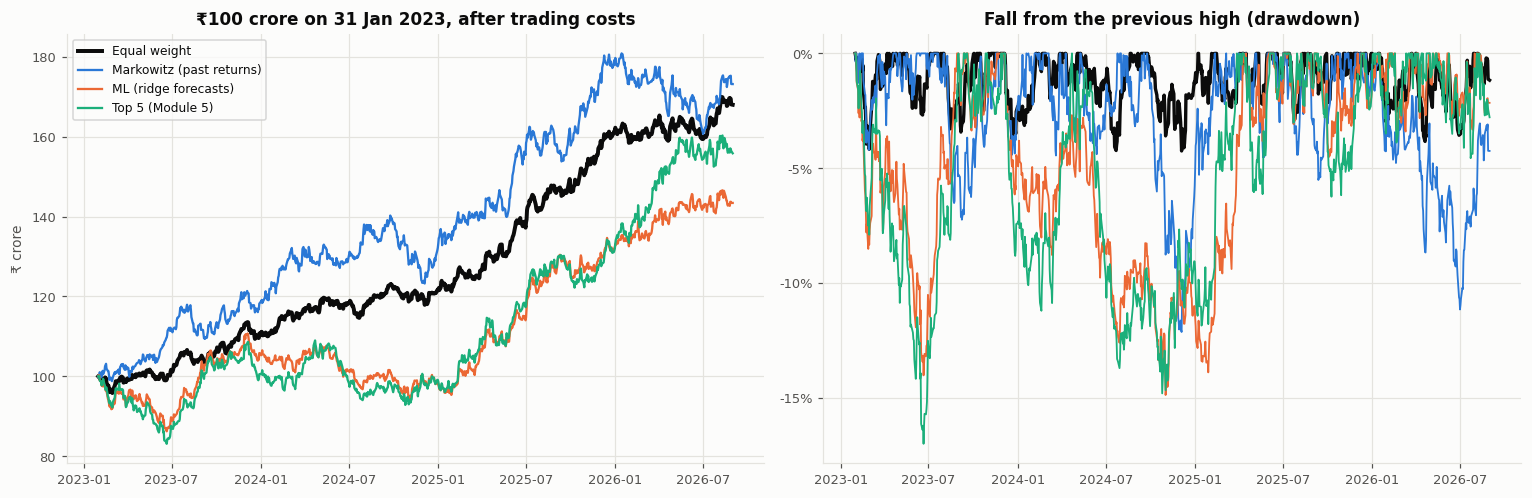

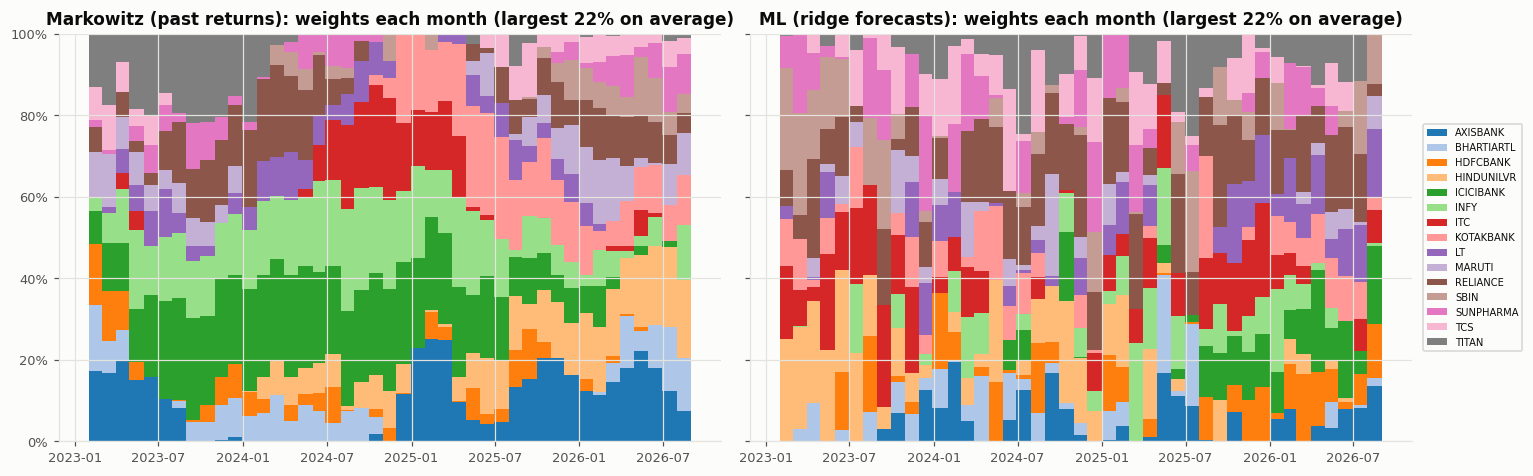

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for s in STRATEGIES:
    value = START_CRORE * (1 + daily[s]).cumprod()
    value = pd.concat([pd.Series([START_CRORE], index=[DATES[0]]), value])
    axes[0].plot(value.index, value, color=COLOURS[s], lw=2.6 if s == EW else 1.5, label=s)
    axes[1].plot(value.index, value / value.cummax() - 1, color=COLOURS[s], lw=2.2 if s == EW else 1.2, label=s)
axes[0].set_ylabel("₹ crore"); axes[0].set_title("₹100 crore on 31 Jan 2023, after trading costs")
axes[0].legend(fontsize=8)
axes[1].yaxis.set_major_locator(plt.MultipleLocator(0.05)); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))     # whole-percent ticks, so no label is rounded
axes[1].set_title("Fall from the previous high (drawdown)")
fig.tight_layout(); save_chart(fig, "01_growth_and_drawdown"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
cmap = plt.get_cmap("tab20")
for ax, s in zip(axes, [MK, ML]):
    w = pd.DataFrame(runs[s]["weights"], index=DATES, columns=TICKERS)
    w.loc[LAST] = w.iloc[-1]                     # extend the last month's weights to 31 Aug 2026 for the chart
    ax.stackplot(w.index, w.T.values, colors=[cmap(i) for i in range(15)], labels=TICKERS, step="post")
    ax.set_title(f"{s}: weights each month (largest {w.iloc[:-1].max(axis=1).mean():.0%} on average)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(0, 1)
axes[1].legend(fontsize=6.5, ncol=1, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout(); save_chart(fig, "02_weights_over_time"); plt.show()

## 6. Checks: other trading costs, and a 0% risk-free rate

- **Costs** (decision M6-04): 0% (before costs, as in Module 5), 0.10% (taxes only), 0.15% (our estimate), 0.30% (pessimistic). The question: **does the order of the strategies change?** Low costs give the busy optimisers their best chance.
- **Risk-free 0%:** Sharpe ratios with no safe-rate deduction, as Module 5's "return per unit of risk". The optimiser still uses 6.8%.

In [7]:
check_rows = []
for c in COST_CHECKS:
    for s in STRATEGIES:
        r = daily[s] if c == COST else backtest(s, cost=c)["daily"]
        check_rows.append({"Cost per ₹ traded": c, "Strategy": s, "CAGR": cagr(r), "Sharpe": sharpe(r)})
cost_checks = pd.DataFrame(check_rows)
show = cost_checks.pivot(index="Strategy", columns="Cost per ₹ traded", values="CAGR").reindex(STRATEGIES)
show.columns = [f"CAGR at {c:.2%}" for c in show.columns]
print("CAGR by trading cost:")
display(show.style.format("{:.1%}"))
best_by_cost = cost_checks.loc[cost_checks.groupby("Cost per ₹ traded").CAGR.idxmax()].set_index("Cost per ₹ traded").Strategy
print("Highest CAGR at each cost:", ", ".join(f"{c:.2%}: {s}" for c, s in best_by_cost.items()))
rf0 = pd.DataFrame({"Strategy": STRATEGIES, "Sharpe at 6.8%": [sharpe(daily[s]) for s in STRATEGIES],
                    "Sharpe at 0%": [sharpe(daily[s], 0.0) for s in STRATEGIES]})
display(rf0.style.format({"Sharpe at 6.8%": "{:.2f}", "Sharpe at 0%": "{:.2f}"}).hide(axis="index"))

CAGR by trading cost:


,CAGR at 0.00%,CAGR at 0.10%,CAGR at 0.15%,CAGR at 0.30%
Strategy,,,,
Equal weight,15.8%,15.7%,15.6%,15.4%
Markowitz (past returns),17.3%,16.8%,16.6%,15.9%
ML (ridge forecasts),12.4%,11.2%,10.6%,8.8%
Top 5 (Module 5),15.2%,13.9%,13.2%,11.2%


Highest CAGR at each cost: 0.00%: Markowitz (past returns), 0.10%: Markowitz (past returns), 0.15%: Markowitz (past returns), 0.30%: Markowitz (past returns)


Strategy,Sharpe at 6.8%,Sharpe at 0%
Equal weight,1.06,1.90
Markowitz (past returns),0.80,1.36
ML (ridge forecasts),0.36,0.93
Top 5 (Module 5),0.51,1.00


## 7. What it means in ₹

₹100 crore invested on 31 Jan 2023, reset every month-end, valued on 31 Aug 2026, **after 0.15% trading costs**:

```text
Value at the end   = ₹100 crore × growth
Gap vs equal weight = value − equal weight's value
Costs paid          ≈ ₹100 crore × 0.15% × total turnover (approximate: the portfolio's size changes over time)
```

In [8]:
money = pd.DataFrame({"Strategy": STRATEGIES})
money["Value on 31 Aug 2026 (₹ crore)"] = [START_CRORE * (1 + daily[s]).prod() for s in STRATEGIES]
ew_value = money.set_index("Strategy").loc[EW, "Value on 31 Aug 2026 (₹ crore)"]
money["Gap vs equal weight (₹ crore)"] = money["Value on 31 Aug 2026 (₹ crore)"] - ew_value
money["Trading costs paid, approx. (₹ crore)"] = [START_CRORE * COST * runs[s]["turnover"].sum() for s in STRATEGIES]
money["Worst fall (₹ crore on ₹100 crore)"] = [START_CRORE * max_drawdown(daily[s]) for s in STRATEGIES]
display(money.style.format({c: "₹{:+.1f}" if "Gap" in c or "Worst" in c else "₹{:.1f}" for c in money.columns if c != "Strategy"})
        .hide(axis="index"))

Strategy,Value on 31 Aug 2026 (₹ crore),Gap vs equal weight (₹ crore),"Trading costs paid, approx. (₹ crore)",Worst fall (₹ crore on ₹100 crore)
Equal weight,₹168.0,₹+0.0,₹0.6,₹-4.2
Markowitz (past returns),₹173.2,₹+5.2,₹2.2,₹-12.1
ML (ridge forecasts),₹143.4,₹-24.6,₹5.8,₹-14.9
Top 5 (Module 5),₹155.9,₹-12.2,₹6.4,₹-17.0


## 8. What the results say

**Answer for Part A: equal weight gives the best return for the risk taken. Neither optimiser beats it beyond luck, and the ML portfolio does worst.**

**Reminder of the measures:** CAGR (yearly growth; higher), volatility (yearly swing; lower), Sharpe (return above the 6.8% safe rate per unit of swing; higher, above 1 good), maximum drawdown (worst fall; closer to 0), turnover (share traded a month; lower), p (chance luck gives a gap this big; real if below 0.017).

### The four strategies (43 test months, 31 Jan 2023 – 31 Aug 2026, after 0.15% trading costs)

| Strategy | CAGR | Volatility | Sharpe | Sortino | Maximum drawdown | Calmar | Turnover a month | Information ratio | p (vs equal weight) | Months beating equal weight (of 43) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| **Equal weight** | 15.6% | **7.8%** | **1.06** | **1.56** | **−4.2%** | **3.67** | **7%** | — | — | — |
| Markowitz (past returns) | **16.6%** | 11.8% | 0.80 | 1.16 | −12.1% | 1.37 | 33% | +0.11 | 0.79 | 22 |
| ML (ridge forecasts) | 10.6% | 11.6% | 0.36 | 0.52 | −14.9% | 0.71 | 90% | −0.62 | 0.39 | 14 |
| Top 5 (Module 5) | 13.2% | 13.3% | 0.51 | 0.73 | −17.0% | 0.78 | 99% | −0.23 | 0.81 | 20 |

- **Equal weight wins on every risk measure:** the highest Sharpe (1.06), Sortino and Calmar; the smallest swing (7.8%), worst fall (−4.2%) and daily VaR (0.76% of value on 95% of days).
- **Markowitz earns the most (16.6% vs 15.6%) but not beyond luck** (p 0.79; it beat equal weight in 22 of 43 months, a coin toss). It took about 1.5 times the swing and nearly 3 times the worst fall for that extra 1%, so its Sharpe is lower (0.80). Its information ratio of +0.11 means about 0.1% extra return per 1% of extra wandering from equal weight: far below the 0.5 that counts as good.
- **The ML portfolio does worst** (10.6%, Sharpe 0.36). It beat equal weight in only 14 of 43 months. Ridge's forecasts carry no skill (Module 5), so the optimiser concentrates money on noise, and trades 90% of the portfolio a month to follow it.
- **Minimum-risk Markowitz = equal weight exactly** (largest weight difference 0.00% over 43 months): with alike, independent stocks, spreading evenly is the lowest-risk mix.

### Checks (step 6)

| Strategy | CAGR at 0% cost | 0.10% | 0.15% | 0.30% | Sharpe at 0% risk-free |
| --- | --- | --- | --- | --- | --- |
| Equal weight | 15.8% | 15.7% | 15.6% | 15.4% | 1.90 |
| Markowitz (past returns) | 17.3% | 16.8% | 16.6% | 15.9% | 1.36 |
| ML (ridge forecasts) | 12.4% | 11.2% | 10.6% | 8.8% | 0.93 |
| Top 5 (Module 5) | 15.2% | 13.9% | 13.2% | 11.2% | 1.00 |

- **The order doesn't change with cost or risk-free rate:** equal weight has the best Sharpe in every case; Markowitz the highest CAGR; ML the lowest.
- **Cost hurts the busy strategies most:** going from 0% to 0.30% costs equal weight 0.4% a year, but ML 3.6% and top 5 4.0%.
- **Before costs equal weight earns 15.8%**, the same as Module 5's "all 15" benchmark: the two modules agree.

### In ₹ (step 7): ₹100 crore on 31 Jan 2023, valued 31 Aug 2026, after costs

| Strategy | Value | vs equal weight | Trading costs paid (approx.) | Worst fall on ₹100 crore |
| --- | --- | --- | --- | --- |
| Equal weight | ₹168.0 crore | — | ₹0.6 crore | −₹4.2 crore |
| Markowitz (past returns) | ₹173.2 crore | +₹5.2 crore | ₹2.2 crore | −₹12.1 crore |
| ML (ridge forecasts) | ₹143.4 crore | −₹24.6 crore | ₹5.8 crore | −₹14.9 crore |
| Top 5 (Module 5) | ₹155.9 crore | −₹12.2 crore | ₹6.4 crore | −₹17.0 crore |

- **Markowitz's +₹5.2 crore came with a worst fall of ₹12.1 crore instead of ₹4.2 crore**, and isn't distinguishable from luck.
- **ML lost ₹24.6 crore against equal weight**, ₹5.8 crore of it in trading costs.

### What it means for the committee
1. **Hold the equity portfolio equally weighted** (or close to it): the best return per unit of risk, the smallest falls, the lowest costs.
2. **Don't optimise on expected returns from this data:** past averages and ML forecasts both fail to predict (Module 5), so optimisers concentrate on noise.
3. **The one useful input to Markowitz here is risk (co-movement), and on this data it points to equal weight.** On real data, where stocks differ in risk and move in groups, minimum-risk weights would differ from equal weight and are worth re-testing.

### What goes to Part B and Module 9
- `daily_returns.csv`: each strategy's daily return after costs, for VaR and stress tests (Part B).
- `FINAL_M6_A_portfolio_weights.csv`: each strategy's weights per month, for stress test (c).
- Equal weight is the recommended equity portfolio; its risk figures from Part B go to Module 9.

## 9. Save the outputs

- **`FINAL_M6_A_portfolio_weights.csv`: ML predictions turned into an actual portfolio** (the brief's first ask; decision M6-13). For every strategy × rebalance date × stock: sector; the weight and how far it sits from equal weight (6.67%); both forecasts side by side (past-year average, used by Markowitz; ridge's forecast, used by ML) and the one this strategy used, with its rank of 15; what was bought or sold at the reset; the stock's actual return that month and its contribution to the portfolio; and the reason in words.
- **`daily_returns.csv`:** each strategy's daily return after costs: **the hand-off to Part B** (VaR, stress tests) and to Module 9.
- **`strategy_comparison.csv`:** the step 4 table. **`cost_checks.csv`:** step 6.
- The charts above and `key_numbers.json`.

In [9]:
SECTOR = mkt.drop_duplicates("Ticker").set_index("Ticker").Sector
BASIS = {MK: "past-year average", ML: "ridge forecast", T5: "ridge forecast"}


def month_return(day) -> np.ndarray:
    """Each stock's compounded return over the holding month that starts at rebalance date `day`."""
    days = R.loc[(R.index > day) & (R.index <= HELD_UNTIL[day])]
    return ((1 + days).prod() - 1).values


def reason(s, t, w, d, mu, rank, actual, contrib):
    """One sentence: what the strategy held in stock t that month, why, and how it turned out."""
    outcome = f"Actual return that month {actual:+.1%}, {'adding' if contrib >= 0 else 'costing'} the portfolio {abs(contrib):.2%}."
    if s == EW:
        return f"Equal weight: 6.67% in every stock, no forecast used. {outcome}"
    if s == T5:
        pick = "in the top 5, 20%" if w > 0 else "outside the top 5, not held"
        return f"Rank {rank} of 15 by ridge's forecast ({mu:+.2%} a month) → {pick}. " + (outcome if w > 0 else "")
    if w < 0.001:
        return f"{s} held none of {t}: its {BASIS[s]} ({mu:+.2%} a month) ranked {rank} of 15, not enough return for its risk."
    cap = "; at the 25% cap" if w >= CAP - 0.001 else ""
    side = "above" if d >= 0 else "below"
    return (f"{s} put {w:.1%} in {t}: its {BASIS[s]} ({mu:+.2%} a month) ranked {rank} of 15; "
            f"{side} equal weight by {abs(d) * 100:.1f} points{cap}. {outcome}")


w_rows = []
for i, day in enumerate(DATES):
    past = R.loc[:day].iloc[-WINDOW:].mean().values * DAYS_A_MONTH
    ridge = ML_FORECAST.loc[day].values
    actual = month_return(day)
    for s in STRATEGIES:
        mu = runs[s]["expected"][i]
        ranks = None if mu is None else pd.Series(mu).rank(ascending=False, method="first").astype(int).values
        for j, t in enumerate(TICKERS):
            w = runs[s]["weights"][i, j]
            trade = w - runs[s]["held_before"][i, j]
            contrib = w * actual[j]
            rank = None if ranks is None else int(ranks[j])
            w_rows.append({"Rebalance date": f"{day:%Y-%m-%d}", "Held until": f"{HELD_UNTIL[day]:%Y-%m-%d}", "Strategy": s,
                           "Ticker": t, "Sector": SECTOR[t], "Weight": w, "Weight vs equal weight (points)": w - 1 / 15,
                           "Past-year average (a month)": past[j], "Ridge forecast (a month)": ridge[j],
                           "Expected return this strategy used": np.nan if mu is None else mu[j],
                           "Rank of that expected return (1 = highest)": rank,
                           "Bought (+) / sold (−) at this reset": trade,
                           "Actual return that month": actual[j],
                           "Contribution to portfolio return (weight × actual)": contrib,
                           "Reason in words": reason(s, t, w, w - 1 / 15, None if mu is None else mu[j], rank, actual[j], contrib)})
weights_out = pd.DataFrame(w_rows)
save_table(weights_out.round(6), "FINAL_M6_A_portfolio_weights")
print(weights_out[(weights_out.Strategy == MK)].iloc[0]["Reason in words"])
print(weights_out[(weights_out.Strategy == ML) & (weights_out.Weight > 0.2)].iloc[0]["Reason in words"])
out = daily.reset_index().rename(columns={"index": "Date"})
out["Date"] = pd.to_datetime(out["Date"]).dt.strftime("%Y-%m-%d")
save_table(out.round(8), "daily_returns")
save_table(results.round(4), "strategy_comparison")
save_table(cost_checks.round(4), "cost_checks")


def r4(v):
    return None if v is None or pd.isna(v) else round(float(v), 4)


res = results.set_index("Strategy")
key = {"days": len(daily), "years": r4(len(daily) / TRADING_DAYS), "trading_days_a_year": TRADING_DAYS,
       "cost": COST, "risk_free": RISK_FREE_ANNUAL, "line": r4(LINE), "min_risk_gap": r4(max(gap)),
       "strategies": {s: {k: r4(res.loc[s, k]) for k in ["CAGR", "Volatility", "Sharpe", "Sortino", "Maximum drawdown",
                                                         "Calmar", "Turnover a month", "VaR 95% (1 day, historical)",
                                                         "CVaR 95% (1 day)", "Largest weight (average)"]
                          + ([] if s == EW else ["p (vs equal weight)", "Information ratio", "Tracking error",
                                                 "Months beating equal weight"])} for s in STRATEGIES},
       "value_crore": {r.Strategy: r4(r["Value on 31 Aug 2026 (₹ crore)"]) for _, r in money.iterrows()},
       "cost_checks": {f"{r['Cost per ₹ traded']:.4f}|{r.Strategy}": r4(r.CAGR) for _, r in cost_checks.iterrows()},
       "any_beats": bool((results.get("Beats equal weight?") == "Yes").any())}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Markowitz (past returns) put 17.3% in AXISBANK: its past-year average (+3.19% a month) ranked 1 of 15; above equal weight by 10.7 points. Actual return that month +3.9%, adding the portfolio 0.68%.
ML (ridge forecasts) put 25.0% in HINDUNILVR: its ridge forecast (+5.96% a month) ranked 1 of 15; above equal weight by 18.3 points; at the 25% cap. Actual return that month -13.4%, costing the portfolio 3.34%.
Saved to module_06_portfolio_optimization/outputs/partA
['01_growth_and_drawdown.png', '02_weights_over_time.png', 'FINAL_M6_A_portfolio_weights.csv', 'cost_checks.csv', 'daily_returns.csv', 'key_numbers.json', 'strategy_comparison.csv']
